# Fig. 1 — lattice Monte Carlo model of protein condensation on a polymer

> Type set for PNAS (`pnas-new`): 8 pt text, 7 pt tick labels, 10 pt panel letters as printed. Writes `fig1/fig1.pdf`. The previous layout is kept in `../alt/fig1/`.

Draws the figure from `processed_data/` and saves `alt/fig1/fig1.pdf`. The rearranged artwork (A, and D split into its three clouds) is in `alt/fig1/art_*`, made once by `alt/fig1/make_alt_art.py`; B and C are `fig1/art_{b,c}.pdf`, scaled.
See `figure_production/README.md` to regenerate the data.

In [1]:
import os

# Reads processed_data/... and art_*.svg relative to figure_production/. Find
# that directory rather than assume the kernel started in it.
DIR_OVERRIDE = None     # set to figure_production's path to skip the search

_SKIP = {"node_modules", "__pycache__", "venv", ".venv", "env", "build", "dist"}


def _ok(d):
    return (os.path.isfile(os.path.join(d, "README.md"))
            and os.path.isdir(os.path.join(d, "processed_data")))


def resolve_figdir():
    if DIR_OVERRIDE:
        if not _ok(DIR_OVERRIDE):
            raise RuntimeError("DIR_OVERRIDE is not figure_production/: " + DIR_OVERRIDE)
        return DIR_OVERRIDE
    starts = []
    nb = globals().get("__vsc_ipynb_file__") or globals().get("__file__")
    if nb:
        starts.append(os.path.dirname(os.path.abspath(nb)))
    starts.append(os.path.abspath(os.getcwd()))
    for start in starts:                      # at or above
        d = start
        for _ in range(6):
            if _ok(d):
                return d
            parent = os.path.dirname(d)
            if parent == d:
                break
            d = parent
    level = [os.path.abspath(os.getcwd())]    # or below, shallowest first
    for _ in range(4):
        nxt = []
        for d in level:
            try:
                names = sorted(os.listdir(d))
            except OSError:
                continue
            for name in names:
                if name.startswith(".") or name in _SKIP:
                    continue
                cand = os.path.join(d, name)
                if not os.path.isdir(cand) or os.path.islink(cand):
                    continue
                if _ok(cand):
                    return cand
                nxt.append(cand)
        level = nxt
    raise RuntimeError(
        "figure_production/ not found from %s -- expected a directory holding "
        "README.md and processed_data/. Set DIR_OVERRIDE above and re-run."
        % os.getcwd())


os.chdir(resolve_figdir())
print("working directory:", os.getcwd())

working directory: /Users/tmora/NextCloudCNRS/Code/droplet/prewet-gene/figure_production


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt


def use_latex():
    plt.rcParams.update({"text.usetex": True, "font.family": "serif",
                         "text.latex.preamble": r"\usepackage{amsmath}"})
    try:
        f = plt.figure()
        f.text(0.5, 0.5, r"$\dfrac{U_{\rm tot}}{k_BT}$ $d^{\rm x}$")
        f.canvas.draw()
        plt.close(f)
        return True
    except Exception as exc:
        plt.close("all")
        # Computer Modern via matplotlib's bundled cmr10, so text widths match
        # the LaTeX render closely (layout checks only)
        plt.rcParams.update({"text.usetex": False, "font.family": "serif",
                             "font.serif": ["cmr10"], "mathtext.fontset": "cm",
                             "axes.formatter.use_mathtext": True})
        print("LaTeX unavailable, falling back to mathtext:",
              type(exc).__name__, str(exc).strip()[:120])
        return False


USETEX = use_latex()
print("usetex:", USETEX)

usetex: True


In [3]:
DATA = "processed_data"
S = json.load(open(os.path.join(DATA, "fig1_scalars.json")))
SK = json.load(open(os.path.join(DATA, "fig1_sketch.json")))       # panel F
T = pd.read_csv(os.path.join(DATA, "fig1_trace.csv"), float_precision="round_trip")
t_trace = np.arange(len(T)) * S["trace"]["mc_samples_per_frame"] / 1e5   # 1e5 MC samples
# B, C are pasted from the source (art_b/c.pdf); their tick labels are re-set here
BC_LABELS = json.load(open(os.path.join("fig1", "art_bc_labels.json")))
# positions of the rearranged artwork (written by fig1/make_alt_art.py)
LAYOUT = json.load(open(os.path.join("fig1", "art_alt_layout.json")))

In [4]:
from matplotlib.patches import FancyArrowPatch

# PNAS (pnas-new, 9pt): \textwidth = 505.69 TeX pt = 504.0 bp, so a figure built
# 481.9 pt wide is printed 1.0459x larger. The type is set so that the PRINTED
# sizes are 8 pt text, 7 pt tick labels and 10 pt panel letters.
PNAS_W, BUILT_W = 504.0, 481.9
PRINT = PNAS_W / BUILT_W
PT_CAPTION, PT_TICK, PT_LETTER = 8 / PRINT, 7 / PRINT, 10 / PRINT
LW, LW_AUX, LW_AXES = 0.5, 0.4, 0.5            # strokes, printed pt (as figs 2-5)

# Everything is placed in source-canvas units (the 350.94-wide canvas of the
# original drawing), K points per unit, page HC units tall.
W = 481.9
CW, CH = 350.94, 340.33
K = W / CW

# ---- alt layout: three rows ------------------------------------------------------
#   row 1: A | B | C      widths 0.4 | 0.3 | 0.3 of the page
#   row 2: D (three clouds on one line, 0.6) | E (0.4)
#   row 3: F, its two traces side by side over the full width
U_AB, U_BC = 0.4 * CW, 0.7 * CW     # column boundaries of row 1
U_DE = 0.6 * CW                     # column boundary of row 2
ROW2 = 103.0                        # top of row 2 (letters D, E)
ROW3 = 189.0                        # top of row 3 (letter F)
HC = 246.0
H = HC * K

RC = {
    "font.size": PT_CAPTION, "axes.labelsize": PT_CAPTION,
    "axes.titlesize": PT_CAPTION, "legend.fontsize": PT_CAPTION,
    "xtick.labelsize": PT_TICK, "ytick.labelsize": PT_TICK,
    "lines.linewidth": LW, "axes.linewidth": LW_AXES,
    "xtick.major.width": LW_AXES, "ytick.major.width": LW_AXES,
    "xtick.minor.width": LW_AUX, "ytick.minor.width": LW_AUX,
    "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.labelpad": 1.5, "xtick.major.pad": 1.5, "ytick.major.pad": 1.5,
    "grid.linewidth": LW_AUX,
    # transparent axes: the artwork goes underneath
    "axes.facecolor": "none",
}


def P(u, v):
    """Canvas point -> figure fraction."""
    return (u * K / W, (HC - v) * K / H)


def R(u0, v0, u1, v1):
    """Canvas box (left, top, right, bottom) -> add_axes rect."""
    return [u0 * K / W, (HC - v1) * K / H, (u1 - u0) * K / W, (v1 - v0) * K / H]


def ctext(u, v, s, **kw):
    """Text at a canvas point."""
    x, y = P(u, v)
    return fig1.text(x, y, s, **kw)


# ---- artwork placements ------------------------------------------------------------
# Each art file holds the WHOLE source canvas with one drawing on it; it is placed
# by a uniform scale s and an offset (du, dv) in canvas units:
#     source point (u, v)  ->  page canvas point (s u + du, s v + dv).
# A's art (fig1/art_a_alt) is already rearranged in page coordinates.
S_BC = 0.68                         # B and C, scaled to 0.3 of the width each
S_D = 1.10                          # D's clouds (60 units across in the source)
D_ORDER = ("free", "open", "closed")    # left to right, as the user listed them
D_CU = (35.0, 105.0, 175.0)             # cloud centres, u (D spans 0 -> U_DE)
D_CV = ROW2 + 1.0 + 33.0                # cloud centres, v


def _place_ink(s, ink_u, ink_v, to_u, to_v):
    """Offsets that put source point (ink_u, ink_v) at page point (to_u, to_v)."""
    return s, to_u - s * ink_u, to_v - s * ink_v


PLACE = {
    "a": ("fig1/art_a_alt", 1.0, 0.0, 0.0),
    # the source ink's top-left: B (8.20, 113.05), C (188.35, 112.66)
    "b": ("fig1/art_b",) + _place_ink(S_BC, 8.20, 113.05, U_AB + 1.1, 3.0),
    "c": ("fig1/art_c",) + _place_ink(S_BC, 188.35, 112.66, U_BC + 1.4, 3.0),
}
for _name, _u in zip(D_ORDER, D_CU):
    _cu, _cv = LAYOUT["d_clouds"][_name]["centre"]
    PLACE["d_" + _name] = ("fig1/art_d_" + _name,) + _place_ink(S_D, _cu, _cv, _u, D_CV)
ART = tuple(PLACE)


def mapped(name, u, v):
    """A source-canvas point of art `name`, where it lands on the page."""
    _, s, du, dv = PLACE[name]
    return s * u + du, s * v + dv


# ---- E and F geometry ------------------------------------------------------------
E_BOX = (237.0, ROW2 + 5.0, 333.0, ROW2 + 70.0)   # E's frame (u0, v0, u1, v1)

# F: the source's row proportions, stretched by F_SCALE; both traces share one
# header line and one set of On/Off levels. Each row's time axis is at Off.
F_SCALE = 1.9
F_TOP = ROW3 + 11.5                 # top of the shaded row; the header sits above it


def _row(ytop, d_on, d_off):
    on = ytop + d_on * F_SCALE
    off = on + d_off * F_SCALE
    return dict(ytop=ytop, on=on, off=off, ybot=off)


F_ROWS = {"polymer": _row(F_TOP, 5.2, 12.9), "free": _row(F_TOP, 5.2, 12.9)}
F_BASE = {"polymer": 0.0, "free": 177.0}   # u of each plot's left edge


print("figure %.1f x %.1f pt = %.3f x %.3f in" % (W, H, W / 72, H / 72))

figure 481.9 x 337.8 pt = 6.693 x 4.692 in


In [5]:
plt.rcParams.update(RC)
fig1 = plt.figure(figsize=(W / 72, H / 72))


<Figure size 669.306x469.166 with 0 Axes>

In [6]:
# ---- A: the polymer on top, the interaction table and the transcription model below
# Positions come from art_alt_layout.json, written with the art by make_alt_art.py.
PU, PV = LAYOUT["poly_d"]                   # the chain's offset from the source


def ptext(u, v, s, **kw):
    """Polymer label at its source position, moved with the chain."""
    return ctext(u + PU, v + PV, s, **kw)


ptext(39.5, 72.9, "Enhancer", ha="center", va="baseline")
# Anchor and Probe pulled apart: at this size they would touch
ptext(91.5, 72.4, "Anchor", ha="center", va="baseline")
ptext(113.6, 72.4, "Probe", ha="center", va="baseline")
ptext(134.8, 72.4, "Ligand", ha="center", va="baseline")
for u, s in ((39.5, "750 bp"), (66.6, "3.75 kb"), (94.6, "750 bp")):
    ptext(u, 92.0, s, ha="center", va="top")

# interaction table: bead symbols centred on U_C, energies aligned on "="
U_C, X_EQ, ROW_V = LAYOUT["u_c"], LAYOUT["x_eq"], LAYOUT["row_v"]
ctext((U_C - 15.7 + X_EQ + 19.0) / 2, LAYOUT["title_v"], "Particle interactions",
      ha="center", va="top")
for v, sym, val in zip(ROW_V, (r"$v$", r"$\eta$", r"$\alpha$", r"$\rho$"),
                       (r"$= +0.5$", r"$= -0.8$", r"$= -1.5$", r"$= -5.0$")):
    ctext(X_EQ - 1.0, v, sym, ha="right", va="center_baseline")
    ctext(X_EQ, v, val, ha="left", va="center_baseline")
ctext(U_C, ROW_V[1], "/", ha="center", va="center_baseline")   # between the eta pairs

# transcription model: the source's labels, moved with its drawing
MU, MV = LAYOUT["model_d"]


def mtext(u, v, s, **kw):
    return ctext(u + MU, v + MV, s, **kw)


mtext(120.7, 8.8, "Transcription model", ha="center", va="top")
mtext(121.0, 20.7, r"$k^+c_{\rm local}$", ha="center", va="center_baseline")
mtext(120.6, 46.0, r"$k^-$", ha="center", va="center_baseline")
# On / Off inside the two states, above their dots (the type is larger than drawn)
mtext(102.9, 33.0, "Off", ha="center", va="baseline", fontsize=PT_TICK)
mtext(138.6, 33.0, "On", ha="center", va="baseline", fontsize=PT_TICK)

# the probe's leader line, from under the probe down to the model's title
pu, pv = LAYOUT["probe"]
(x0, y0), (x1, y1) = P(pu - 0.2, pv + 3.6), P(MU + 120.7 + 6.5, MV + 8.8 - 1.2)
fig1.add_artist(plt.Line2D([x0, x1], [y0, y1], color="black", lw=LW,
                           solid_capstyle="round"))

In [7]:
# ---- D: labels -------------------------------------------------------------
# The user's placements in the source canvas, moved (and scaled) with each cloud.
def dtext(cloud, u, v, s, **kw):
    return ctext(*mapped("d_" + cloud, u, v), s, **kw)


dtext("free", 269.4, 9.2, "Free\nreceptor", ha="center", va="top", linespacing=1.0)
dtext("closed", 241.0, 57.3, "Closed\npolymer", ha="center", va="top", linespacing=1.0)
dtext("open", 297.8, 57.6, "Open polymer", ha="center", va="top")
dtext("open", 297.8, 67.5, "or without enhancer", ha="center", va="top")

Text(0.2961635607226306, 0.505151117886179, 'or without enhancer')

In [8]:
# ---- B, C: lattice configurations ---------------------------------------------
# Pasted from the source (art_b/c.pdf), scaled by S_BC; only their tick labels
# are re-set here, at the glyphs' (moved) positions, multiples of 10 only. The
# axis letters x, y, z are dropped.
# Data behind them: 20260423 sweep, c = 0.003 run 13 (B) and c = 0.017 run 2 (C).
for panel in ("b", "c"):
    for lab in BC_LABELS[panel]:
        if lab["text"] in ("x", "y", "z") or int(lab["text"]) % 10:
            continue
        ctext(*mapped(panel, lab["u"], lab["v"]), lab["text"],   # upright, as in the source
              ha="center", va="center", fontsize=PT_TICK)

In [9]:
# E_BOX (geometry cell): E's frame, to the right of D
aE = fig1.add_axes(R(*E_BOX))
t = t_trace
aE.plot(t, T["activity_smoothed"], color="black", alpha=0.7, lw=LW, zorder=3)
aE.set_xlim(0, t[-1])                         # starts at 0, no margin
aE.set_ylim(0.07, 0.61)                        # 0.1 clears the corner's "0.0"
aE.set_yticks(np.arange(0.1, 0.61, 0.1))
aE.set_ylabel("Smoothed\ntranscription activity", linespacing=1.0)
aE.set_xlabel(r"Time ($\times 10^5$ Monte Carlo samples)")
aE2 = aE.twinx()
aE2.plot(t, T["distance"], color="orange", alpha=0.5, lw=LW)
aE2.set_ylim(0, 50)
aE2.set_ylabel("Probe-enhancer distance", color="orange")
aE.set_zorder(aE2.get_zorder() + 1)

In [10]:
# ---- F: the two traces side by side, sharing one header line ---------------------
# Each plot keeps the source's horizontal layout, shifted by F_BASE (geometry cell):
# y-axis title, On/Off, the arrow axis, then the trace from X0 to X1.
aF = fig1.add_axes(R(0.0, ROW3, CW, HC))
aF.set_xlim(0.0, CW); aF.set_ylim(HC, ROW3)
aF.axis("off")
ARR = dict(arrowstyle="-|>", mutation_scale=5, lw=LW_AXES, color="black", shrinkA=0, shrinkB=0)
HDR = F_TOP - 2.4                             # header baseline
rp, rf = F_ROWS["polymer"], F_ROWS["free"]

for tag, r in F_ROWS.items():
    b = F_BASE[tag]
    X0, X1, YAX = b + 26.4, b + 167.5, b + 21.3
    fx = lambda tt, X0=X0, X1=X1: X0 + np.asarray(tt) * (X1 - X0)
    r["fx"], r["X1"] = fx, X1
    yv = lambda lev, r=r: r["off"] + (r["on"] - r["off"]) * np.asarray(lev)
    aF.plot(fx(SK[tag]["t"]), yv(SK[tag]["level"]), color="black", lw=LW, zorder=3,
            solid_joinstyle="miter")
    aF.add_patch(FancyArrowPatch((YAX, r["ybot"]), (YAX, r["ytop"] - 0.5), **ARR))   # y axis
    for y, s_ in ((r["on"], "On"), (r["off"], "Off")):
        aF.plot([YAX - 1.7, YAX], [y, y], color="black", lw=LW_AXES)
        aF.text(YAX - 2.7, y, s_, ha="right", va="center_baseline", fontsize=PT_TICK)
    aF.text(b + 5.6, (r["ytop"] + r["ybot"]) / 2, "Transcription", rotation=90,
            ha="center", va="center")
    aF.plot([YAX, X1 - 0.5], [r["off"]] * 2, color="black", lw=LW_AXES)      # time axis, at Off
    aF.text(X1, r["ybot"] + 2.6, "Time", ha="right", va="top")

for sp in SK["spans"]:
    fx = rp["fx"]
    aF.fill_between([fx(sp["t0"]), fx(sp["t1"])], rp["ytop"], rp["ybot"] + 0.1,
                    color="red" if sp["state"] == "closed" else "#1c9900", alpha=0.18, lw=0)


def bracket(r, t0, t1, y, label, mark_top, mark_bot):
    fx = r["fx"]
    for tt in (t0, t1):
        aF.plot([fx(tt)] * 2, [mark_top, mark_bot], color="black", alpha=0.3, lw=LW_AUX)
    aF.add_patch(FancyArrowPatch((fx(t0), y), (fx(t1), y), arrowstyle="<|-|>",
                                 mutation_scale=3.5, lw=LW_AUX, color="black", shrinkA=0, shrinkB=0))
    aF.text((fx(t0) + fx(t1)) / 2, y + 1.4, label, ha="center", va="top")


# markers, brackets and their labels keep the source's offsets from each row
pm, fm = SK["polymer_marks"], SK["free_marks"]
bracket(rp, pm[0], pm[1], rp["ybot"] + 2.2, r"$T^{\rm x}$", rp["on"] + 3.7, rp["ybot"] + 2.4)
bracket(rp, pm[1], pm[2], rp["ybot"] + 2.2, r"$T^{\rm o}$", rp["on"] + 3.7, rp["ybot"] + 2.4)
bracket(rf, fm[0], fm[1], rf["ybot"] + 2.2, r"$T^-$", rf["on"] + 4.4, rf["ybot"] + 2.4)
bracket(rf, fm[2], fm[3], rf["ybot"] + 2.2, r"$T^+$", rf["on"] + 4.4, rf["ybot"] + 2.4)
# headers, one line for both: the states, left, and the cycle time, right
b = F_BASE["polymer"]
aF.text(b + 22.5, HDR, "Closed polymer", color="red", ha="left", va="baseline")
aF.text(b + 71.5, HDR, "Open polymer", color="#1c9900", ha="left", va="baseline")
aF.text(rp["X1"], HDR, r"$\tau_p = \langle T^{\rm x}\rangle + \langle T^{\rm o}\rangle$", ha="right", va="baseline")
aF.text(F_BASE["free"] + 22.5, HDR, "Free receptor", ha="left", va="baseline")
aF.text(rf["X1"], HDR, r"$\tau_r = \langle T^-\rangle + \langle T^+\rangle$", ha="right", va="baseline")

Text(344.5, 198.1, '$\\tau_r = \\langle T^-\\rangle + \\langle T^+\\rangle$')

In [11]:
# ---- panel letters ----------------------------------------------------------------
for (u, v), s in (((0.7, 1.0), "A"), ((U_AB + 0.2, 1.0), "B"), ((U_BC + 0.2, 1.0), "C"),
                  ((0.7, ROW2), "D"), ((U_DE + 0.9, ROW2), "E"), ((0.7, ROW3), "F")):
    x, y = P(u, v)
    fig1.text(x, y, s, usetex=False, fontfamily="Arial", fontsize=PT_LETTER, ha="left", va="top")

Saved figure to fig1/fig1.pdf
artwork:
  a         fig1/art_a_alt         scale 1.000, canvas offset (   0.0,    0.0)
  b         fig1/art_b             scale 0.680, canvas offset ( 135.9,  -73.9)
  c         fig1/art_c             scale 0.680, canvas offset ( 119.0,  -73.6)
  d_free    fig1/art_d_free        scale 1.100, canvas offset (-261.7,  103.6)
  d_open    fig1/art_d_open        scale 1.100, canvas offset (-223.6,   47.5)
  d_closed  fig1/art_d_closed      scale 1.100, canvas offset ( -90.1,   47.5)


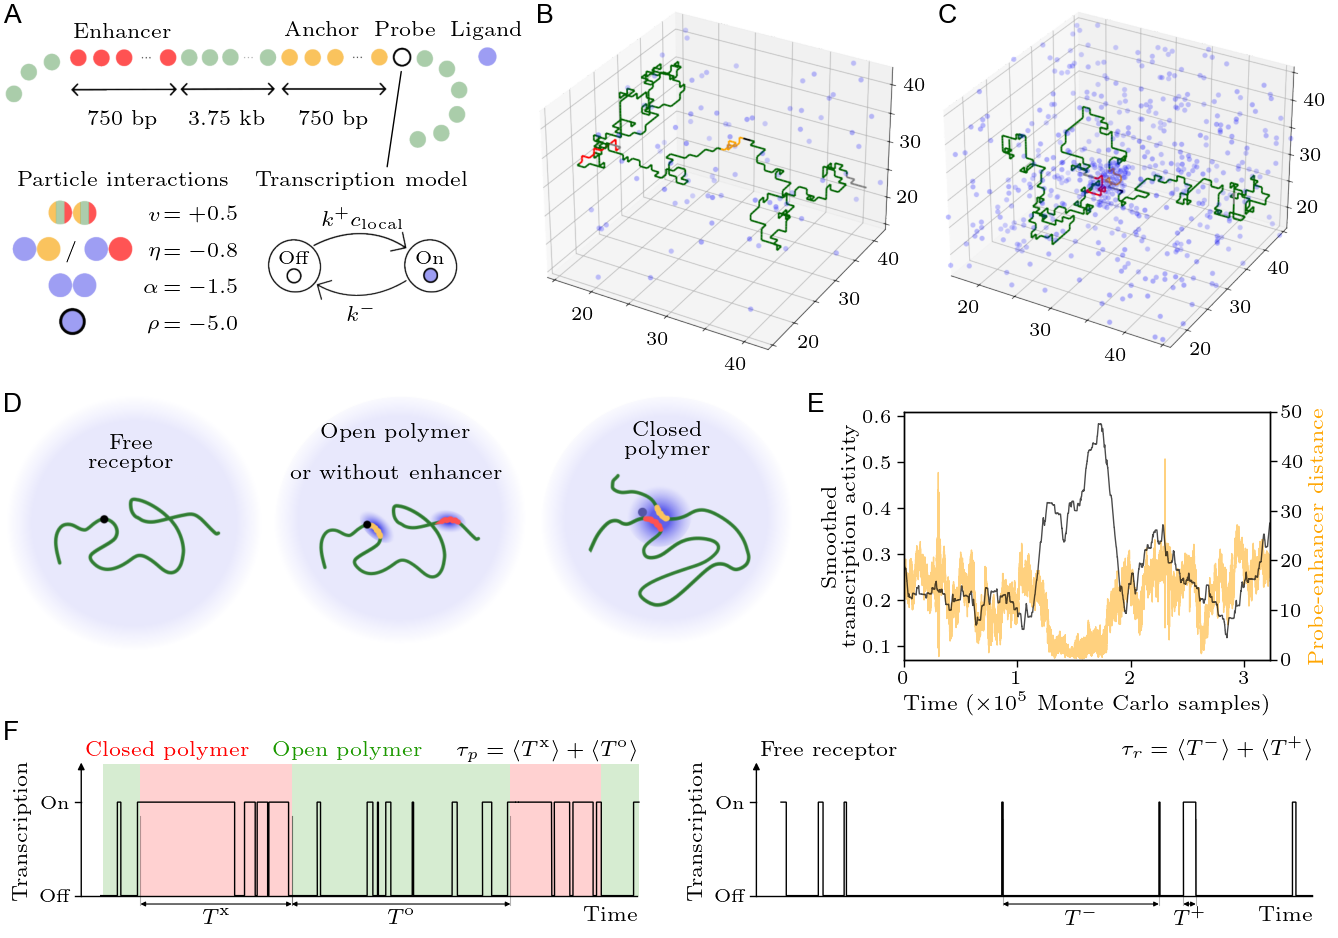

In [12]:
# ---- save, then composite the artwork underneath -------------------------------
path = os.path.join("fig1", "fig1.pdf")   # art: PLACE, geometry cell
fig1.savefig(path, format="pdf", transparent=True)
# no bbox_inches: that would re-crop the page and lose \textwidth.
# transparent=True: the artwork goes UNDER this layer, and matplotlib's white
# figure patch would otherwise cover it.
print("Saved figure to", path)


def _cairosvg():
    """cairosvg, or None if it cannot actually be used. `pip install cairosvg` on
    macOS leaves it importable but unusable (no cairo C library; cairocffi raises
    OSError, not ImportError), so every use falls back to Inkscape on any failure.
    Homebrew's cairo lives in /opt/homebrew/lib, which python.org Python never
    searches; point ctypes.util.find_library at it before the import."""
    import ctypes.util
    brew = "/opt/homebrew/lib/libcairo.2.dylib"
    if os.path.exists(brew) and not getattr(ctypes.util, "_brew_cairo", False):
        _find = ctypes.util.find_library
        ctypes.util.find_library = lambda name: (
            brew if name in ("cairo-2", "cairo", "libcairo-2") else _find(name))
        ctypes.util._brew_cairo = True
    try:
        import cairosvg
        return cairosvg
    except Exception:
        return None


def _inkscape():
    """Inkscape's CLI; on macOS an app bundle, not on PATH."""
    import shutil
    exe = shutil.which("inkscape")
    if exe:
        return exe
    for cand in ("/Applications/Inkscape.app/Contents/MacOS/inkscape",
                 os.path.expanduser("~/Applications/Inkscape.app/Contents/MacOS/inkscape")):
        if os.path.exists(cand):
            return cand
    return None


def svg_to_pdf(svg_path, pdf_path):
    """SVG -> PDF. The page box is read back by the caller, never assumed."""
    cs = _cairosvg()
    if cs is not None:
        try:
            cs.svg2pdf(url=svg_path, write_to=pdf_path)
            return "cairosvg"
        except Exception:
            pass
    import subprocess
    exe = _inkscape()
    if exe:
        subprocess.run([exe, svg_path, "--export-type=pdf", "--export-area-page",
                        "--export-filename=" + pdf_path], check=True, capture_output=True)
        return "inkscape"
    raise RuntimeError("no working SVG converter: install Inkscape, or cairosvg "
                       "plus the cairo C library (brew install cairo)")


def svg_to_png(svg_path, width_px):
    """SVG -> PNG bytes, for the inline preview only."""
    cs = _cairosvg()
    if cs is not None:
        try:
            return cs.svg2png(url=svg_path, output_width=width_px)
        except Exception:
            pass
    exe = _inkscape()
    if exe is None:
        return None
    import subprocess, tempfile
    tmp = os.path.join(tempfile.mkdtemp(), "preview.png")
    subprocess.run([exe, svg_path, "--export-type=png", "--export-area-page",
                    "--export-width=%d" % width_px, "--export-filename=" + tmp],
                   check=True, capture_output=True)
    data = open(tmp, "rb").read()
    os.remove(tmp)
    return data


def stamp_artwork(page_pdf, names):
    """Lay every art PDF down on a blank page, placed as PLACE says (geometry
    cell), then put the transparent matplotlib layer over the top: type over
    drawing. Each art PDF is the whole source canvas: source point (u, v) goes to
    page canvas point (s u + du, s v + dv), i.e. to page points (K x, H - K y)."""
    from pypdf import PdfReader, PdfWriter, Transformation, PageObject
    out = PageObject.create_blank_page(width=W, height=H)
    for name in names:
        stem, s, du, dv = PLACE[name]
        art = PdfReader(stem + ".pdf").pages[0]
        bw, bh = float(art.mediabox.width), float(art.mediabox.height)
        f = K * s * CW / bw
        assert abs(K * s * CH / bh - f) < 0.01 * f, "%s: non-uniform scale" % name
        out.merge_transformed_page(
            art, Transformation().scale(f).translate(K * du, H - K * (s * CH + dv)))
        print("  %-9s %-22s scale %.3f, canvas offset (%6.1f, %6.1f)" % (name, stem, s, du, dv))
    out.merge_page(PdfReader(page_pdf).pages[0])
    wr = PdfWriter(); wr.add_page(out)
    with open(page_pdf, "wb") as fh:
        wr.write(fh)


def _missing_deps():
    import importlib.util as iu
    missing = []
    if iu.find_spec("pypdf") is None:
        missing.append("pypdf")
    return missing


_missing = _missing_deps()
if _missing:
    print("\nThe artwork was NOT added: missing %s. The figure is saved without it.\n"
          "    pip install pypdf        # always needed\n"
          "    and either Inkscape, or: pip install cairosvg && brew install cairo\n"
          % ", ".join(_missing))
else:
    print("artwork:")
    stamp_artwork(path, ART)

# ---- inline preview: a raster copy of the artwork, added after savefig ---------
def preview_artwork(dpi=300):
    import io
    import matplotlib.image as mpimg
    for name in ART:
        stem, sc, du, dv = PLACE[name]
        buf = svg_to_png(stem + ".svg", max(int(sc * CW * K / 72 * dpi), 1))
        if buf is None:
            return False
        ax = fig1.add_axes(R(du, dv, du + sc * CW, dv + sc * CH), zorder=-1)
        ax.imshow(mpimg.imread(io.BytesIO(buf), format="png"), interpolation="bilinear",
                  aspect="auto")
        ax.set_axis_off()
    return True


if not preview_artwork():
    print("(no inline preview of the artwork: neither cairosvg nor Inkscape found)")

# The art axes span the whole source canvas, past the page edges; the inline
# backend's tight bbox would include them, so show a page-sized PNG instead.
import io
from IPython.display import Image, display
_buf = io.BytesIO()
fig1.savefig(_buf, format="png", dpi=200, facecolor="white")
display(Image(_buf.getvalue(), width=900))